# Classificação Supervisionada de Doenças Cardiovasculares na Coorte NHANES 2021–2023

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/brunorcorrea/FT108A-final-project/blob/main/nhanes-cvd-diagnosis.ipynb)

**Disciplina:** FT108A – Introdução ao Aprendizado de Máquina (2s 2026) — Faculdade de Tecnologia (UNICAMP)

**Integrantes do Grupo:**
- Bruno Ricardo Corrêa (RA: 260759)
- Cristiane Brandão Cobo (RA: 288831)
- Gustavo Bilia Marques (RA: 279808)
- Julio Morino Anastácio (RA: 173434)
- Sabrina Tomaz Barbosa (RA: 324065)

---
Este notebook implementa o pipeline experimental para a disciplina **FT108A**, aplicando e comparando cinco algoritmos de aprendizado de máquina supervisionado (**Regressão Logística, KNN, Árvore de Decisão, Random Forest e XGBoost**) na classificação binária da presença/registro de doenças cardiovasculares (DCV) utilizando **20 variáveis preditoras** da coorte **NHANES 2021–2023** ($N = 3.947$ casos completos via `dropna`).

Os dados são divididos de forma estratificada em **Treino (70%)**, **Validação (15%)** e **Teste (15%)**, avaliando e comparando sistematicamente **três cenários de balanceamento** para todos os 5 modelos:
1. **Sem Reamostragem (Baseline):** Distribuição original desbalanceada.
2. **SMOTE (Over-sampling):** Geração sintética de exemplos da classe minoritária no conjunto de treino.
3. **RandomUnderSampler (Under-sampling):** Subamostragem aleatória da classe majoritária no conjunto de treino.

## 1. Instalação e Importação de Bibliotecas

In [1]:
# Instalação de pacotes necessários (caso não estejam presentes no ambiente)
# %pip install -q scikit-learn imbalanced-learn xgboost pandas numpy matplotlib seaborn scipy

In [2]:
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings('ignore')
os.environ['LOKY_MAX_CPU_COUNT'] = '10'
os.makedirs('figuras', exist_ok=True)

# Semente global para reprodutibilidade
FIXED_RANDOM_STATE = 42

## 2. Carregamento dos Dados e Definição da Coorte
O questionário de condições médicas do NHANES (variáveis `MCQ160B` a `MCQ160F`) é aplicado apenas a adultos com **20 anos ou mais**. Além disso, participantes gestantes (`RIDEXPRG == 1`) são excluídas para evitar alterações fisiológicas transitórias nos biomarcadores e medidas antropométricas.

A variável alvo binária (`target`) indica a presença (`1`) ou ausência (`0`) de registro de qualquer uma das cinco condições cardiovasculares investigadas:
- `MCQ160B`: Insuficiência cardíaca congestiva (*Congestive heart failure*)
- `MCQ160C`: Doença arterial coronariana (*Coronary heart disease*)
- `MCQ160D`: Angina (*Angina pectoris*)
- `MCQ160E`: Infarto agudo do miocárdio (*Heart attack*)
- `MCQ160F`: Acidente vascular cerebral (*Stroke*)

In [3]:
# 1. Leitura da base consolidada NHANES 2021-2023 (baixa automaticamente do GitHub se estiver no Google Colab)
DATA_PATH = 'data/nhanes_2021_2023_merged_data.csv'
RAW_GITHUB_URL = 'https://raw.githubusercontent.com/brunorcorrea/FT108A-final-project/main/data/nhanes_2021_2023_merged_data.csv'

if not os.path.exists(DATA_PATH):
    os.makedirs('data', exist_ok=True)
    print('Baixando dataset do GitHub para o ambiente Google Colab...')
    urllib.request.urlretrieve(RAW_GITHUB_URL, DATA_PATH)

cvd_df = pd.read_csv(DATA_PATH)
print(f"Total de participantes na base bruta: {len(cvd_df)}")

# 2. Filtro de adultos (>= 20 anos)
cvd_df = cvd_df[cvd_df['RIDAGEYR'] >= 20].copy()
print(f"Total após filtro de adultos (>= 20 anos): {len(cvd_df)}")

# 3. Construção da variável alvo binária (target)
target_cols = ['MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F']
cvd_df[target_cols] = cvd_df[target_cols].replace([7, 9], pd.NA)  # 7 = Recusou, 9 = Não sabe

has_positive_diagnosis = (cvd_df[target_cols] == 1.0).any(axis=1)
is_undetermined = (~has_positive_diagnosis) & (cvd_df[target_cols].isna().any(axis=1))

cvd_df = cvd_df[~is_undetermined].copy()
cvd_df['target'] = has_positive_diagnosis[~is_undetermined].astype(int)

# 4. Exclusão de gestantes (RIDEXPRG == 1)
cvd_df = cvd_df[cvd_df['RIDEXPRG'] != 1].copy()
cvd_df.reset_index(drop=True, inplace=True)

print(f"Coorte elegível antes da remoção de ausentes: N = {len(cvd_df)}")

Total de participantes na base bruta: 11933
Total após filtro de adultos (>= 20 anos): 7809
Coorte elegível antes da remoção de ausentes: N = 7723


## 3. Limpeza, Seleção das 20 Variáveis Preditoras e Remoção de Dados Ausentes (`dropna`)
Nesta etapa:
1. Códigos especiais do NHANES para recusa ou desconhecimento (`7`, `9`, `77`, `99`) são convertidos em `NaN`.
2. As leituras de pressão arterial (`sys_bp1`, `dia_bp1`) são consolidadas pela média da 2ª e 3ª aferições (com *fallback* para a 1ª leitura), e os lipídios (`tc_mgdl`, `tg_mgdl`) utilizam o painel bioquímico caso a amostra de referência esteja ausente.
3. São derivadas as variáveis categóricas de tabagismo (`smk_cat`) e consumo de álcool (`alc_cat`).
4. São selecionadas exatamente as **20 variáveis preditoras** (12 numéricas contínuas e 8 categóricas/binárias) mais a variável alvo (`target`).
5. **Análise de Casos Completos (`dropna`):** Os registros com valores ausentes nas 20 variáveis são removidos (`dropna()`), preservando apenas observações completas.

In [4]:
# Mapeamento dos códigos originais do NHANES para nomes legíveis
column_names = {
    'RIDAGEYR': 'age',
    'RIAGENDR': 'gender',
    'RIDRETH1': 'race',
    'DMDEDUC2': 'education',
    'INDFMPIR': 'poverty_ratio',
    'BMXBMI': 'bmi',
    'BMXWAIST': 'waist_circ_cm',
    'BPXOSY1': 'sys_bp1', 'BPXOSY2': 'sys_bp2', 'BPXOSY3': 'sys_bp3',
    'BPXODI1': 'dia_bp1', 'BPXODI2': 'dia_bp2', 'BPXODI3': 'dia_bp3',
    'LBXTC': 'tc_mgdl', 'LBXSCH': 'tc_bch_mgdl',
    'LBDHDD': 'hdl_mgdl',
    'LBXTLG': 'tg_mgdl', 'LBXSTR': 'tg_bch_mgdl',
    'LBXGH': 'hba1c',
    'LBXHSCRP': 'crp_mgl',
    'LBXSCR': 's_creat_mgdl',
    'DIQ010': 'diab_diag',
    'BPQ020': 'high_bp_diag',
    'BPQ080': 'high_chol_diag',
    'SMQ020': 'smk_100', 'SMQ040': 'smk_status',
    'ALQ111': 'alc_ever', 'ALQ121': 'alc_freq_12m', 'ALQ151': 'alc_5_daily',
}
cvd_df = cvd_df.rename(columns=column_names).copy()

# Correção de underflow numérico de arquivos SAS XPORT (valores ~1e-79 -> 0.0)
num_cols_all = cvd_df.select_dtypes(include=[np.number]).columns
cvd_df[num_cols_all] = cvd_df[num_cols_all].mask(cvd_df[num_cols_all].abs() < 1e-50, 0.0)

# Limpeza de variáveis binárias de histórico clínico (1 = Sim, 2 = Não -> 0, 7/9 -> NaN)
for c in ['high_bp_diag', 'high_chol_diag', 'diab_diag']:
    cvd_df[c] = cvd_df[c].replace({2: 0, 7: np.nan, 9: np.nan})
cvd_df['diab_diag'] = cvd_df['diab_diag'].replace({3: 0})  # 3 = Pré-diabetes mapeado para ausência de DM clínico

# Limpeza de códigos de recusa/desconhecimento em variáveis demográficas e comportamentais
cvd_df['education'] = cvd_df['education'].replace({7: np.nan, 9: np.nan})
for c in ['smk_100', 'smk_status', 'alc_ever', 'alc_5_daily']:
    cvd_df[c] = cvd_df[c].replace({7: np.nan, 9: np.nan})
cvd_df['alc_freq_12m'] = cvd_df['alc_freq_12m'].replace({77: np.nan, 99: np.nan})

# Consolidação da Pressão Arterial (média da 2ª e 3ª leituras com fallback para a 1ª)
cvd_df['sys_bp1'] = cvd_df[['sys_bp2', 'sys_bp3']].mean(axis=1).fillna(cvd_df['sys_bp1'])
cvd_df['dia_bp1'] = cvd_df[['dia_bp2', 'dia_bp3']].mean(axis=1).fillna(cvd_df['dia_bp1'])

# Consolidação de Colesterol Total e Triglicerídeos com fallback do painel bioquímico
if 'tc_bch_mgdl' in cvd_df.columns:
    cvd_df['tc_mgdl'] = cvd_df['tc_mgdl'].fillna(cvd_df['tc_bch_mgdl'])
if 'tg_bch_mgdl' in cvd_df.columns:
    cvd_df['tg_mgdl'] = cvd_df['tg_mgdl'].fillna(cvd_df['tg_bch_mgdl'])

# Categorização de Tabagismo (0: Nunca fumou, 1: Fumante diário, 2: Fumante ocasional, 3: Ex-fumante)
smoking_conditions = [
    (cvd_df['smk_100'] == 2),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 1),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 2),
    (cvd_df['smk_100'] == 1) & (cvd_df['smk_status'] == 3),
]
cvd_df['smk_cat'] = np.select(smoking_conditions, [0, 1, 2, 3], default=np.nan)

# Categorização de Consumo de Álcool (0: Abstêmio, 1: Ocasional, 2: Moderado, 3: Intenso)
alcohol_conditions = [
    (cvd_df['alc_ever'] == 2) | (cvd_df['alc_freq_12m'] == 0),
    (cvd_df['alc_5_daily'] == 1) | (cvd_df['alc_freq_12m'].isin([1, 2])),
    (cvd_df['alc_freq_12m'].isin([3, 4, 5, 6])),
    (cvd_df['alc_freq_12m'].isin([7, 8, 9, 10])),
]
cvd_df['alc_cat'] = np.select(alcohol_conditions, [0, 3, 2, 1], default=np.nan)

# Definição das 20 variáveis preditoras (12 contínuas + 8 categóricas)
continuous_cols = [
    'age', 'poverty_ratio', 'bmi', 'waist_circ_cm',
    'sys_bp1', 'dia_bp1', 'tc_mgdl', 'hdl_mgdl',
    'tg_mgdl', 'hba1c', 'crp_mgl', 's_creat_mgdl'
]
categorical_cols = [
    'gender', 'race', 'education', 'smk_cat',
    'alc_cat', 'diab_diag', 'high_bp_diag', 'high_chol_diag'
]

predictor_cols = continuous_cols + categorical_cols
assert len(predictor_cols) == 20, f"Esperadas 20 variáveis preditoras, encontradas {len(predictor_cols)}"

# Seleção dos 20 atributos + target e remoção de linhas com valores ausentes (dropna)
subset_cvd_df = cvd_df[predictor_cols + ['target']].dropna().reset_index(drop=True)

print(f"Dimensões após dropna() (Casos Completos): {subset_cvd_df.shape[0]} linhas x {subset_cvd_df.shape[1]} colunas (20 preditores + target)")
print(f"Total de valores ausentes restantes: {subset_cvd_df.isnull().sum().sum()}")
print("\nDistribuição da variável alvo (target) nos casos completos:")
print(subset_cvd_df['target'].value_counts().rename({0: '0 (Ausente)', 1: '1 (Presente)'}))
print((subset_cvd_df['target'].value_counts(normalize=True).rename({0: '0 (Ausente) %', 1: '1 (Presente) %'}) * 100).round(2))
display(subset_cvd_df.head())

Dimensões após dropna() (Casos Completos): 3947 linhas x 21 colunas (20 preditores + target)
Total de valores ausentes restantes: 0

Distribuição da variável alvo (target) nos casos completos:
target
0 (Ausente)     3497
1 (Presente)     450
Name: count, dtype: int64
target
0 (Ausente) %     88.6
1 (Presente) %    11.4
Name: proportion, dtype: float64


,age,poverty_ratio,bmi,waist_circ_cm,sys_bp1,dia_bp1,tc_mgdl,hdl_mgdl,tg_mgdl,hba1c,...,s_creat_mgdl,gender,race,education,smk_cat,alc_cat,diab_diag,high_bp_diag,high_chol_diag,target
0,66.0,5.00,33.5,114.7,115.0,76.0,214.0,60.0,86.0,5.6,...,0.79,1.0,3.0,5.0,3.0,3.0,0.0,1.0,0.0,0
1,44.0,1.41,29.7,93.5,108.0,78.0,187.0,49.0,375.0,6.2,...,0.64,2.0,2.0,3.0,0.0,1.0,1.0,0.0,1.0,0
2,34.0,1.33,30.2,106.1,117.5,74.5,183.0,46.0,142.0,5.1,...,0.82,1.0,1.0,4.0,3.0,2.0,0.0,0.0,0.0,0
3,68.0,1.32,42.6,122.0,140.5,76.0,203.0,42.0,111.0,5.9,...,0.76,2.0,3.0,5.0,0.0,0.0,0.0,1.0,1.0,0
4,33.0,0.93,38.9,123.8,106.5,72.5,157.0,41.0,265.0,5.4,...,0.55,2.0,3.0,3.0,1.0,0.0,0.0,0.0,0.0,0


## 4. Análise Exploratória dos Dados (EDA)
Abaixo inspecionamos as estatísticas descritivas da amostra de casos completos ($N = 3.947$), a distribuição da variável alvo (`target`) por sexo, a separabilidade das principais variáveis contínuas por diagnóstico cardiovascular e a matriz de correlação de Spearman.

In [5]:
# Estatísticas descritivas das 12 variáveis contínuas (Casos Completos)
display(subset_cvd_df[continuous_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,3947.0,53.93,16.70,20.00,40.00,58.00,67.00,80.00
poverty_ratio,3947.0,3.10,1.63,0.00,1.65,3.11,5.00,5.00
bmi,3947.0,29.66,6.89,15.20,24.70,28.50,33.50,68.90
waist_circ_cm,3947.0,101.09,16.67,62.40,89.10,99.70,111.30,187.00
sys_bp1,3947.0,122.23,16.90,65.00,110.50,120.50,132.00,210.00
dia_bp1,3947.0,74.55,10.64,31.50,67.00,74.00,81.00,137.50
tc_mgdl,3947.0,189.13,42.28,62.00,160.00,187.00,215.00,438.00
hdl_mgdl,3947.0,54.78,14.95,22.00,44.00,53.00,63.00,138.00
tg_mgdl,3947.0,134.43,100.65,25.00,78.00,109.00,157.00,1745.00
hba1c,3947.0,5.75,1.05,3.60,5.20,5.50,5.90,17.10


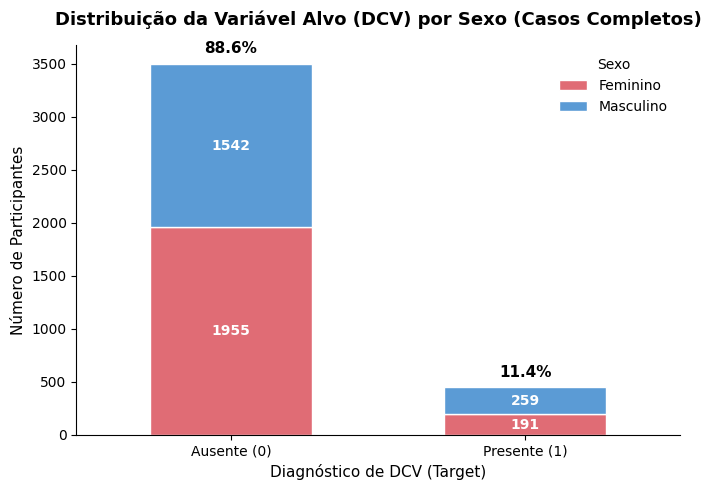

In [6]:
# Distribuição de Doença Cardiovascular (CVD) por Sexo
plot_df = subset_cvd_df.copy()
plot_df['target_label'] = plot_df['target'].map({0: 'Ausente (0)', 1: 'Presente (1)'})
plot_df['gender_label'] = plot_df['gender'].map({1: 'Masculino', 2: 'Feminino'})

counts_df = plot_df.groupby(['target_label', 'gender_label']).size().unstack().reindex(['Ausente (0)', 'Presente (1)'])

fig, ax = plt.subplots(figsize=(7, 5))
counts_df.plot(
    kind='bar', stacked=True, ax=ax,
    color={'Masculino': '#5b9bd5', 'Feminino': '#e06c75'},
    width=0.55, edgecolor='white'
)

for p in ax.patches:
    w, h = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if h > 0:
        ax.text(x + w / 2, y + h / 2, f'{int(h)}', ha='center', va='center', color='white', fontweight='bold', fontsize=10)

totals = counts_df.sum(axis=1)
for i, total in enumerate(totals):
    pct = (total / len(plot_df)) * 100
    ax.text(i, total + totals.max() * 0.02, f"{pct:.1f}%", ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_title('Distribuição da Variável Alvo (DCV) por Sexo (Casos Completos)', fontweight='bold', fontsize=13, pad=15)
ax.set_xlabel('Diagnóstico de DCV (Target)', fontsize=11)
ax.set_ylabel('Número de Participantes', fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(title='Sexo', frameon=False)
plt.tight_layout()
plt.show()

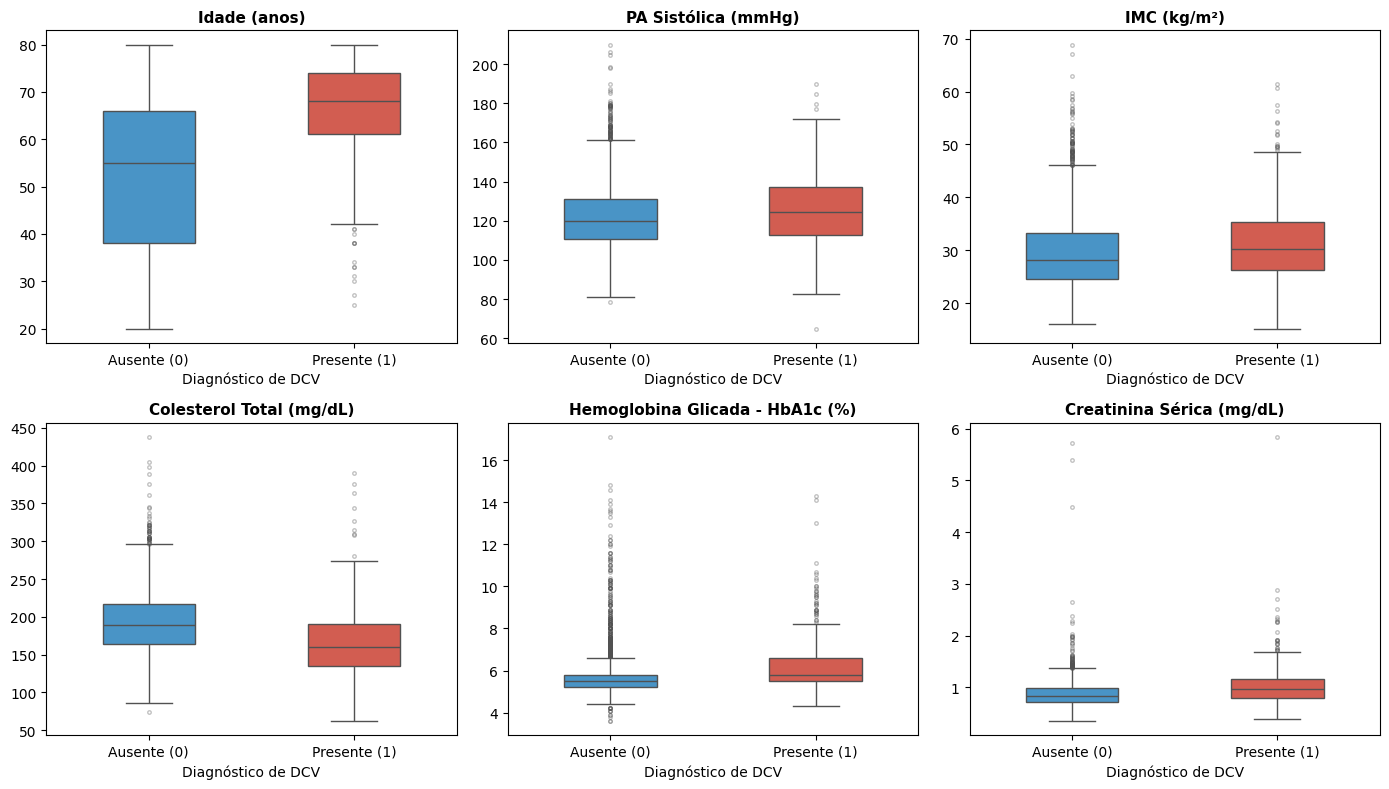

In [7]:
# Boxplots das principais variáveis contínuas por diagnóstico de DCV
box_vars = [
    ('age', 'Idade (anos)'),
    ('sys_bp1', 'PA Sistólica (mmHg)'),
    ('bmi', 'IMC (kg/m²)'),
    ('tc_mgdl', 'Colesterol Total (mg/dL)'),
    ('hba1c', 'Hemoglobina Glicada - HbA1c (%)'),
    ('s_creat_mgdl', 'Creatinina Sérica (mg/dL)')
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8))
axes = axes.flatten()

for i, (col, title) in enumerate(box_vars):
    sns.boxplot(
        data=plot_df, x='target_label', y=col, hue='target_label',
        ax=axes[i], palette={'Ausente (0)': '#3498db', 'Presente (1)': '#e74c3c'},
        legend=False, width=0.45, flierprops={'marker': 'o', 'markersize': 2.5, 'alpha': 0.35}
    )
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Diagnóstico de DCV', fontsize=10)
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

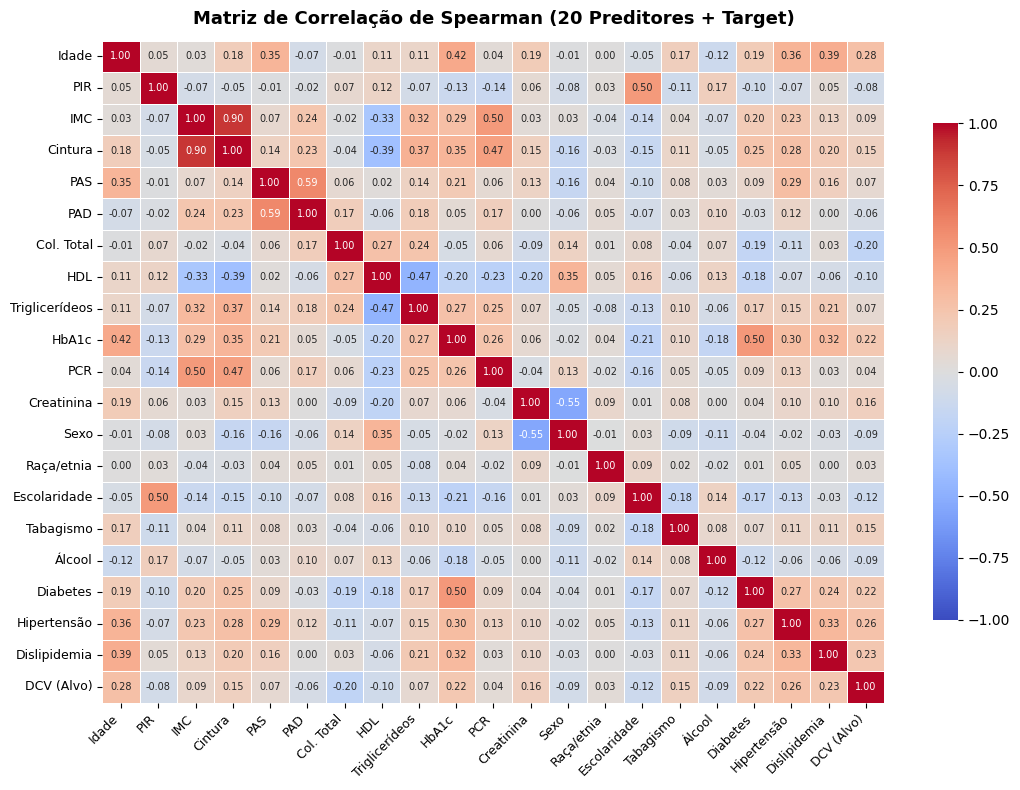

In [8]:
# Matriz de Correlação de Spearman das 20 variáveis preditoras + target
labels_pt = {
    'age': 'Idade', 'gender': 'Sexo', 'race': 'Raça/etnia',
    'education': 'Escolaridade', 'poverty_ratio': 'PIR',
    'bmi': 'IMC', 'waist_circ_cm': 'Cintura',
    'sys_bp1': 'PAS', 'dia_bp1': 'PAD',
    'tc_mgdl': 'Col. Total', 'hdl_mgdl': 'HDL', 'tg_mgdl': 'Triglicerídeos',
    'hba1c': 'HbA1c', 'crp_mgl': 'PCR', 's_creat_mgdl': 'Creatinina',
    'smk_cat': 'Tabagismo', 'alc_cat': 'Álcool',
    'diab_diag': 'Diabetes', 'high_bp_diag': 'Hipertensão',
    'high_chol_diag': 'Dislipidemia', 'target': 'DCV (Alvo)'
}

corr = subset_cvd_df.corr(method='spearman').rename(index=labels_pt, columns=labels_pt)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr, annot=True, fmt='.2f', annot_kws={'size': 7},
    cmap='coolwarm', vmin=-1, vmax=1, center=0,
    linewidths=0.4, linecolor='white', cbar_kws={'shrink': 0.75}, ax=ax
)
ax.set_title('Matriz de Correlação de Spearman (20 Preditores + Target)', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('figuras/matriz-de-correlacao.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Divisão Estratificada em Treino (70%), Validação (15%) e Teste (15%)
Para garantir rigor metodológico e ausência de vazamento de informações (*data leakage*), o dataset completo ($N = 3.947$) é dividido de forma estratificada em **três subconjuntos mutuamente exclusivos**:
1. **Conjunto de Treinamento (70% — $2.762$ amostras):** Utilizado para ajuste do `ColumnTransformer`, aplicação das técnicas de reamostragem (`Sem Reamostragem`, `SMOTE` e `RandomUnderSampler`) e busca de hiperparâmetros com validação cruzada ($k=5$).
2. **Conjunto de Validação (15% — $592$ amostras):** Conjunto intermediário independente utilizado para monitorar e comparar o desempenho das 3 abordagens de balanceamento e dos 5 algoritmos após o ajuste.
3. **Conjunto de Teste (15% — $593$ amostras):** Conjunto *holdout* final estritamente isolado para reportar as métricas definitivas do artigo, curvas ROC e matrizes de confusão.

In [9]:
X = subset_cvd_df[predictor_cols].copy()
y = subset_cvd_df['target'].copy()

# 1ª etapa: Separa 70% para Treinamento e 30% temporários (Validação + Teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=FIXED_RANDOM_STATE, stratify=y
)

# 2ª etapa: Divide os 30% temporários igualmente em 15% Validação e 15% Teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=FIXED_RANDOM_STATE, stratify=y_temp
)

print(f"Conjunto de Treinamento (70%): {X_train.shape[0]} amostras | Positivos: {(y_train == 1).sum()} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto de Validação   (15%): {X_val.shape[0]} amostras | Positivos: {(y_val == 1).sum()} ({y_val.mean()*100:.2f}%)")
print(f"Conjunto de Teste       (15%): {X_test.shape[0]} amostras | Positivos: {(y_test == 1).sum()} ({y_test.mean()*100:.2f}%)")

# ColumnTransformer sem imputação (dados já completos via dropna)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# As 3 abordagens de balanceamento a serem comparadas
sampling_strategies = {
    "Sem Reamostragem": 'passthrough',
    "SMOTE": SMOTE(random_state=FIXED_RANDOM_STATE),
    "RandomUnderSampler": RandomUnderSampler(random_state=FIXED_RANDOM_STATE),
}

# Os 5 modelos base
base_estimators = {
    "Logistic Regression": LogisticRegression(max_iter=1000, solver='liblinear', random_state=FIXED_RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=FIXED_RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=FIXED_RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(tree_method='hist', eval_metric='logloss', random_state=FIXED_RANDOM_STATE, n_jobs=-1),
}

Conjunto de Treinamento (70%): 2762 amostras | Positivos: 315 (11.40%)
Conjunto de Validação   (15%): 592 amostras | Positivos: 67 (11.32%)
Conjunto de Teste       (15%): 593 amostras | Positivos: 68 (11.47%)


## 6. Treinamento ($k = 5$) e Avaliação no Conjunto de Validação (15%)
Para cada combinação de **Abordagem de Balanceamento (3)** $	imes$ **Algoritmo (5)** (totalizando **15 experimentos**), executa-se o `RandomizedSearchCV` (`n_iter=20`) no conjunto de **Treinamento (70%)** otimizando o **F2-Score** ($eta = 2$), e avalia-se o modelo ajustado no **Conjunto de Validação (15%)**.

In [10]:
param_distributions = {
    "Logistic Regression": {
        'model__C': loguniform(0.01, 10.0),
        'model__penalty': ['l1', 'l2']
    },
    "KNN": {
        'model__n_neighbors': randint(3, 31),
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    "Decision Tree": {
        'model__max_depth': randint(3, 16),
        'model__min_samples_split': randint(2, 20),
        'model__min_samples_leaf': randint(2, 15),
        'model__criterion': ['gini', 'entropy']
    },
    "Random Forest": {
        'model__n_estimators': randint(100, 400),
        'model__max_depth': randint(4, 16),
        'model__min_samples_split': randint(2, 20),
        'model__min_samples_leaf': randint(2, 12),
        'model__max_features': ['sqrt', 'log2']
    },
    "XGBoost": {
        'model__n_estimators': randint(100, 400),
        'model__learning_rate': loguniform(0.01, 0.15),
        'model__max_depth': randint(2, 8),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.6, 0.4)
    }
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=FIXED_RANDOM_STATE)
f2_scorer = make_scorer(fbeta_score, beta=2)

best_models = {}       # best_models[(strategy_name, model_name)]
val_results = []

for strategy_name, sampler_obj in sampling_strategies.items():
    print(f"\n=======================================================")
    print(f" ABORDAGEM: {strategy_name}")
    print(f"=======================================================")
    for model_name, estimator in base_estimators.items():
        pipeline = ImbPipeline([
            ('preprocessor', preprocessor),
            ('sampler', sampler_obj),
            ('model', estimator)
        ])

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_distributions[model_name],
            n_iter=20,
            scoring=f2_scorer,
            cv=cv_strategy,
            random_state=FIXED_RANDOM_STATE,
            n_jobs=-1,
            refit=True
        )
        search.fit(X_train, y_train)
        best_model = search.best_estimator_
        best_models[(strategy_name, model_name)] = best_model

        # Avaliação no Conjunto de Validação (15%)
        y_val_pred = best_model.predict(X_val)
        y_val_prob = best_model.predict_proba(X_val)[:, 1]
        val_f2 = fbeta_score(y_val, y_val_pred, beta=2, zero_division=0)
        val_auc = roc_auc_score(y_val, y_val_prob)

        clean_params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
        val_results.append({
            "Abordagem": strategy_name,
            "Modelo": model_name,
            "F2 (CV Treino)": round(search.best_score_, 4),
            "F2 (Validação)": round(val_f2, 4),
            "Recall (Validação)": round(recall_score(y_val, y_val_pred, zero_division=0), 4),
            "AUC-ROC (Validação)": round(val_auc, 4),
            "Melhores Hiperparâmetros": clean_params
        })
        print(f"  [{model_name}] F2 (CV): {search.best_score_:.4f} | F2 (Val): {val_f2:.4f} | AUC (Val): {val_auc:.4f}")

df_val_results = pd.DataFrame(val_results).set_index(["Abordagem", "Modelo"])
print("\n=== DESEMPENHO NO CONJUNTO DE VALIDAÇÃO (15%) ===")
display(df_val_results)


 ABORDAGEM: Sem Reamostragem


  [Logistic Regression] F2 (CV): 0.2421 | F2 (Val): 0.2613 | AUC (Val): 0.8331


  [KNN] F2 (CV): 0.1909 | F2 (Val): 0.1852 | AUC (Val): 0.6917


  [Decision Tree] F2 (CV): 0.3021 | F2 (Val): 0.3182 | AUC (Val): 0.6630


  [Random Forest] F2 (CV): 0.1063 | F2 (Val): 0.1601 | AUC (Val): 0.8472


  [XGBoost] F2 (CV): 0.2698 | F2 (Val): 0.2551 | AUC (Val): 0.8467

 ABORDAGEM: SMOTE


... (7 outputs left out)

  [Decision Tree] F2 (CV): 0.5213 | F2 (Val): 0.5388 | AUC (Val): 0.8031


  [Random Forest] F2 (CV): 0.5951 | F2 (Val): 0.5579 | AUC (Val): 0.8415


  [XGBoost] F2 (CV): 0.5873 | F2 (Val): 0.5757 | AUC (Val): 0.8523

=== DESEMPENHO NO CONJUNTO DE VALIDAÇÃO (15%) ===


F2 (CV Treino)  F2 (Validação)  \
Abordagem          Modelo                                                
Sem Reamostragem   Logistic Regression          0.2421          0.2613   
                   KNN                          0.1909          0.1852   
                   Decision Tree                0.3021          0.3182   
                   Random Forest                0.1063          0.1601   
                   XGBoost                      0.2698          0.2551   
SMOTE              Logistic Regression          0.5990          0.5482   
                   KNN                          0.5478          0.5010   
                   Decision Tree                0.4907          0.5349   
                   Random Forest                0.5542          0.5128   
                   XGBoost                      0.5491          0.5161   
RandomUnderSampler Logistic Regression          0.5976          0.5324   
                   KNN                          0.5665          0.5692   
                   Decision Tree                0.5213          0.5388   
                   Random Forest                0.5951          0.5579   
                   XGBoost                      0.5873          0.5757   

                                        Recall (Validação)  \
Abordagem          Modelo                                    
Sem Reamostragem   Logistic Regression              0.2239   
                   KNN                              0.1642   
                   Decision Tree                    0.3134   
                   Random Forest                    0.1343   
                   XGBoost                          0.2239   
SMOTE              Logistic Regression              0.7463   
                   KNN                              0.7463   
                   Decision Tree                    0.7313   
                   Random Forest                    0.6567   
                   XGBoost                          0.6716   
RandomUnderSampler Logistic Regression              0.7612   
                   KNN                              0.7612   
                   Decision Tree                    0.7463   
                   Random Forest                    0.8060   
                   XGBoost                          0.8060   

                                        AUC-ROC (Validação)  \
Abordagem          Modelo                                     
Sem Reamostragem   Logistic Regression               0.8331   
                   KNN                               0.6917   
                   Decision Tree                     0.6630   
                   Random Forest                     0.8472   
                   XGBoost                           0.8467   
SMOTE              Logistic Regression               0.8281   
                   KNN                               0.7824   
                   Decision Tree                     0.7954   
                   Random Forest                     0.8226   
                   XGBoost                           0.8252   
RandomUnderSampler Logistic Regression               0.8198   
                   KNN                               0.8182   
                   Decision Tree                     0.8031   
                   Random Forest                     0.8415   
                   XGBoost                           0.8523   

                                                                 Melhores Hiperparâmetros  
Abordagem          Modelo                                                                  
Sem Reamostragem   Logistic Regression         {'C': 1.3311216080736887, 'penalty': 'l2'}  
                   KNN                  {'n_neighbors': 4, 'p': 2, 'weights': 'distance'}  
                   Decision Tree        {'criterion': 'entropy', 'max_depth': 14, 'min...  
                   Random Forest        {'max_depth': 15, 'max_features': 'sqrt', 'min...  
                   XGBoost              {'colsample_bytree': 0.602208846849441, 'learn...  
SMOTE     

## 7. Avaliação Final no Conjunto de Teste Independente (Holdout 15%)
Por fim, avaliamos os **15 modelos ajustados** (3 abordagens $	imes$ 5 algoritmos) no **Conjunto de Teste Independente ($N_{	ext{teste}} = 593$, 15%)**, comparando **Acurácia, Precisão, Recall, F1-Score, F2-Score e AUC-ROC**.

In [11]:
results = []
cnf_matrices = {}
roc_values = {}

for (strategy_name, model_name), model in best_models.items():
    y_pred_final = model.predict(X_test)
    y_prob_final = model.predict_proba(X_test)[:, 1]

    roc_auc = roc_auc_score(y_test, y_prob_final)
    fpr, tpr, _ = roc_curve(y_test, y_prob_final)

    roc_values[(strategy_name, model_name)] = {"FPR": fpr, "TPR": tpr, "AUC": roc_auc}
    cnf_matrices[(strategy_name, model_name)] = confusion_matrix(y_test, y_pred_final)

    results.append({
        "Abordagem": strategy_name,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred_final),
        "Precision": precision_score(y_test, y_pred_final, zero_division=0),
        "Recall": recall_score(y_test, y_pred_final, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_final, zero_division=0),
        "F2-Score": fbeta_score(y_test, y_pred_final, beta=2, zero_division=0),
        "AUC-ROC": roc_auc
    })

df_teste_final = pd.DataFrame(results)
print("=== TABELA COMPLETA DE DESEMPENHO NO TESTE FINAL (15% HOLDOUT — 3 ABORDAGENS x 5 MODELOS) ===")
display(df_teste_final.set_index(["Abordagem", "Model"]).round(4))

# Tabelas Dinâmicas (Pivot) para comparação direta entre as 3 abordagens
col_order = ["Sem Reamostragem", "SMOTE", "RandomUnderSampler"]
model_order = list(base_estimators.keys())

for metric in ["F2-Score", "Recall", "AUC-ROC", "Accuracy"]:
    piv = df_teste_final.pivot(index="Model", columns="Abordagem", values=metric).loc[model_order, col_order]
    print(f"\n--- Comparação Direta no Teste: {metric} ---")
    display(piv.round(4))

=== TABELA COMPLETA DE DESEMPENHO NO TESTE FINAL (15% HOLDOUT — 3 ABORDAGENS x 5 MODELOS) ===


Accuracy  Precision  Recall  F1-Score  \
Abordagem          Model                                                        
Sem Reamostragem   Logistic Regression    0.8820     0.4500  0.1324    0.2045   
                   KNN                    0.8583     0.2895  0.1618    0.2075   
                   Decision Tree          0.8331     0.2459  0.2206    0.2326   
                   Random Forest          0.8836     0.4444  0.0588    0.1039   
                   XGBoost                0.8820     0.4643  0.1912    0.2708   
SMOTE              Logistic Regression    0.7622     0.2890  0.7353    0.4149   
                   KNN                    0.6627     0.2080  0.6912    0.3197   
                   Decision Tree          0.7420     0.2515  0.6324    0.3598   
                   Random Forest          0.7875     0.3014  0.6471    0.4112   
                   XGBoost                0.7723     0.2866  0.6618    0.4000   
RandomUnderSampler Logistic Regression    0.7302     0.2653  0.7647    0.3939   
                   KNN                    0.7352     0.2620  0.7206    0.3843   
                   Decision Tree          0.7133     0.2316  0.6471    0.3411   
                   Random Forest          0.7218     0.2563  0.7500    0.3820   
                   XGBoost                0.7352     0.2620  0.7206    0.3843   

                                        F2-Score  AUC-ROC  
Abordagem          Model                                   
Sem Reamostragem   Logistic Regression    0.1541   0.8182  
                   KNN                    0.1774   0.6536  
                   Decision Tree          0.2252   0.6190  
                   Random Forest          0.0712   0.8030  
                   XGBoost                0.2167   0.8100  
SMOTE              Logistic Regression    0.5618   0.8247  
                   KNN                    0.4719   0.7416  
                   Decision Tree          0.4853   0.7578  
                   Random Forest          0.5263   0.8275  
                   XGBoost                0.5245   0.8251  
RandomUnderSampler Logistic Regression    0.5556   0.8069  
                   KNN                    0.5338   0.7791  
                   Decision Tree          0.4762   0.7104  
                   Random Forest          0.5414   0.8151  
                   XGBoost                0.5338   0.8101


--- Comparação Direta no Teste: F2-Score ---


Abordagem,Sem Reamostragem,SMOTE,RandomUnderSampler
Model,,,
Logistic Regression,0.1541,0.5618,0.5556
KNN,0.1774,0.4719,0.5338
Decision Tree,0.2252,0.4853,0.4762
Random Forest,0.0712,0.5263,0.5414
XGBoost,0.2167,0.5245,0.5338



--- Comparação Direta no Teste: Recall ---


Abordagem,Sem Reamostragem,SMOTE,RandomUnderSampler
Model,,,
Logistic Regression,0.1324,0.7353,0.7647
KNN,0.1618,0.6912,0.7206
Decision Tree,0.2206,0.6324,0.6471
Random Forest,0.0588,0.6471,0.7500
XGBoost,0.1912,0.6618,0.7206



--- Comparação Direta no Teste: AUC-ROC ---


Abordagem,Sem Reamostragem,SMOTE,RandomUnderSampler
Model,,,
Logistic Regression,0.8182,0.8247,0.8069
KNN,0.6536,0.7416,0.7791
Decision Tree,0.6190,0.7578,0.7104
Random Forest,0.8030,0.8275,0.8151
XGBoost,0.8100,0.8251,0.8101



--- Comparação Direta no Teste: Accuracy ---


Abordagem,Sem Reamostragem,SMOTE,RandomUnderSampler
Model,,,
Logistic Regression,0.8820,0.7622,0.7302
KNN,0.8583,0.6627,0.7352
Decision Tree,0.8331,0.7420,0.7133
Random Forest,0.8836,0.7875,0.7218
XGBoost,0.8820,0.7723,0.7352


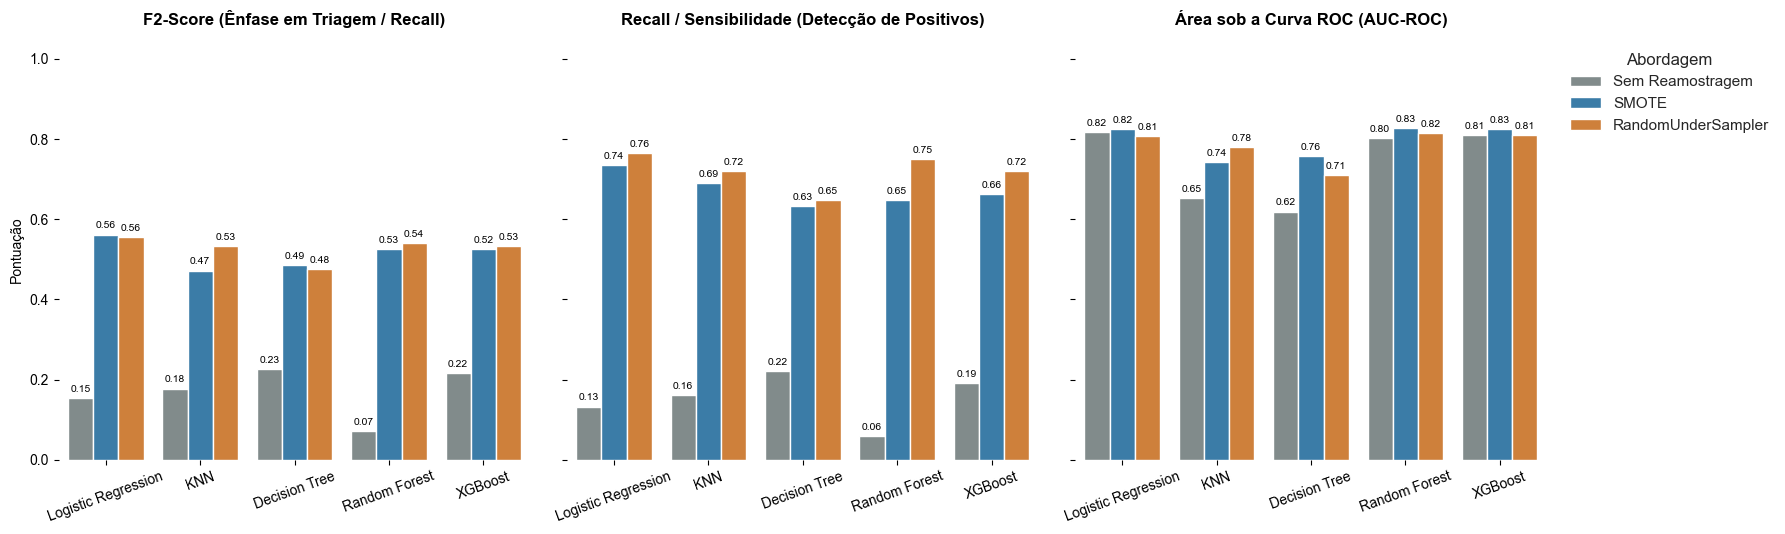

In [12]:
# Gráfico comparativo entre Sem Reamostragem, SMOTE e RandomUnderSampler (F2-Score, Recall e AUC-ROC)
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5.5), sharey=True)
sns.set_theme(style="whitegrid")
palette_strat = {
    "Sem Reamostragem": "#7f8c8d",
    "SMOTE": "#2980b9",
    "RandomUnderSampler": "#e67e22"
}

metrics_to_plot = [
    ("F2-Score", "F2-Score (Ênfase em Triagem / Recall)"),
    ("Recall", "Recall / Sensibilidade (Detecção de Positivos)"),
    ("AUC-ROC", "Área sob a Curva ROC (AUC-ROC)")
]

for idx, (metric_col, title) in enumerate(metrics_to_plot):
    ax = axes[idx]
    sns.barplot(
        data=df_teste_final, x="Model", y=metric_col, hue="Abordagem",
        hue_order=["Sem Reamostragem", "SMOTE", "RandomUnderSampler"],
        palette=palette_strat, ax=ax
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Pontuação" if idx == 0 else "")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=20, labelsize=10)

    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(
                f'{h:.2f}',
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom',
                xytext=(0, 3), textcoords='offset points',
                fontsize=7.5, color='black'
            )

    if idx < 2:
        ax.get_legend().remove()
    else:
        ax.legend(title="Abordagem", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('figuras/metricas-teste-holdout.png', dpi=300, bbox_inches='tight')
plt.show()

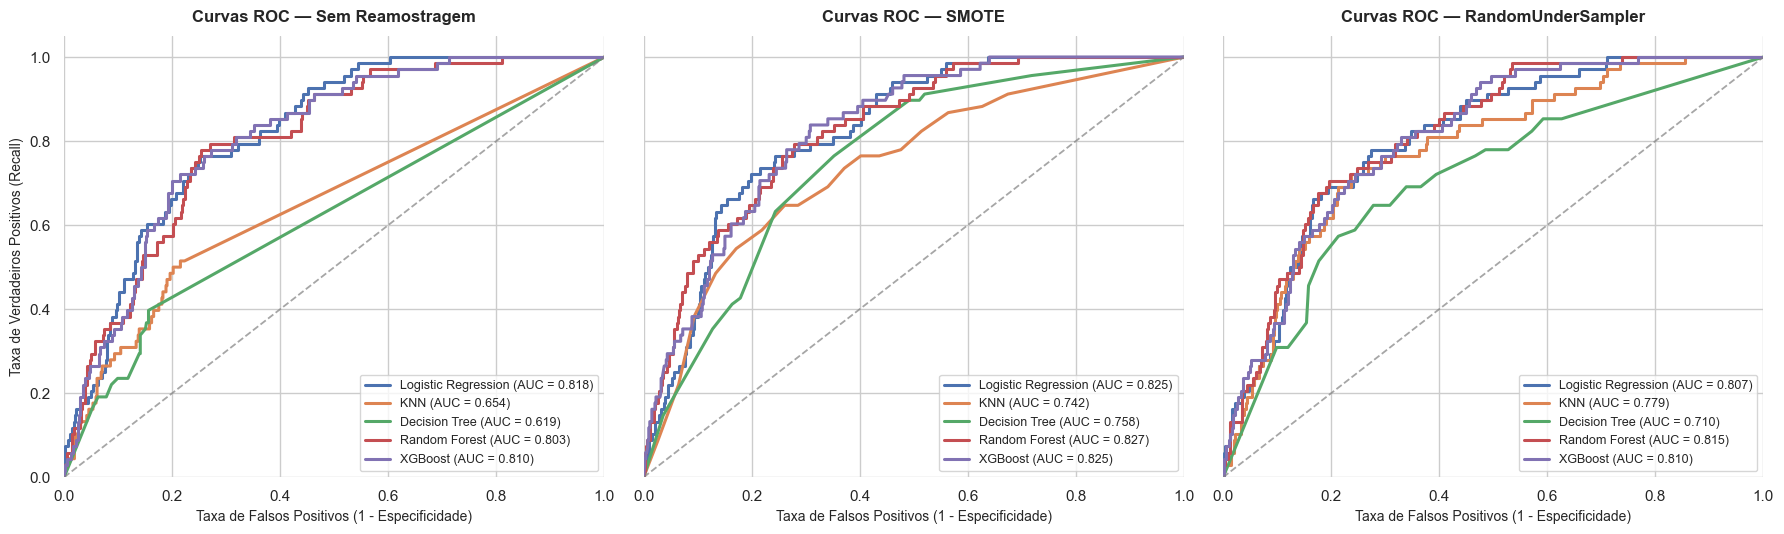

In [13]:
# Curvas ROC Comparativas para as 3 Abordagens
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5.5), sharey=True)
sns.set_theme(style="whitegrid", palette="deep")

for idx, strategy_name in enumerate(["Sem Reamostragem", "SMOTE", "RandomUnderSampler"]):
    ax = axes[idx]
    for model_name in base_estimators.keys():
        curva = roc_values[(strategy_name, model_name)]
        ax.plot(
            curva["FPR"], curva["TPR"],
            linewidth=2.2,
            label=f"{model_name} (AUC = {curva['AUC']:.3f})"
        )
    ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.3, alpha=0.7)
    ax.set_title(f"Curvas ROC — {strategy_name}", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Taxa de Falsos Positivos (1 - Especificidade)", fontsize=10)
    if idx == 0:
        ax.set_ylabel("Taxa de Verdadeiros Positivos (Recall)", fontsize=10)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc="lower right", fontsize=9, frameon=True)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('figuras/auc-roc-baseline.png', dpi=300, bbox_inches='tight')
plt.show()

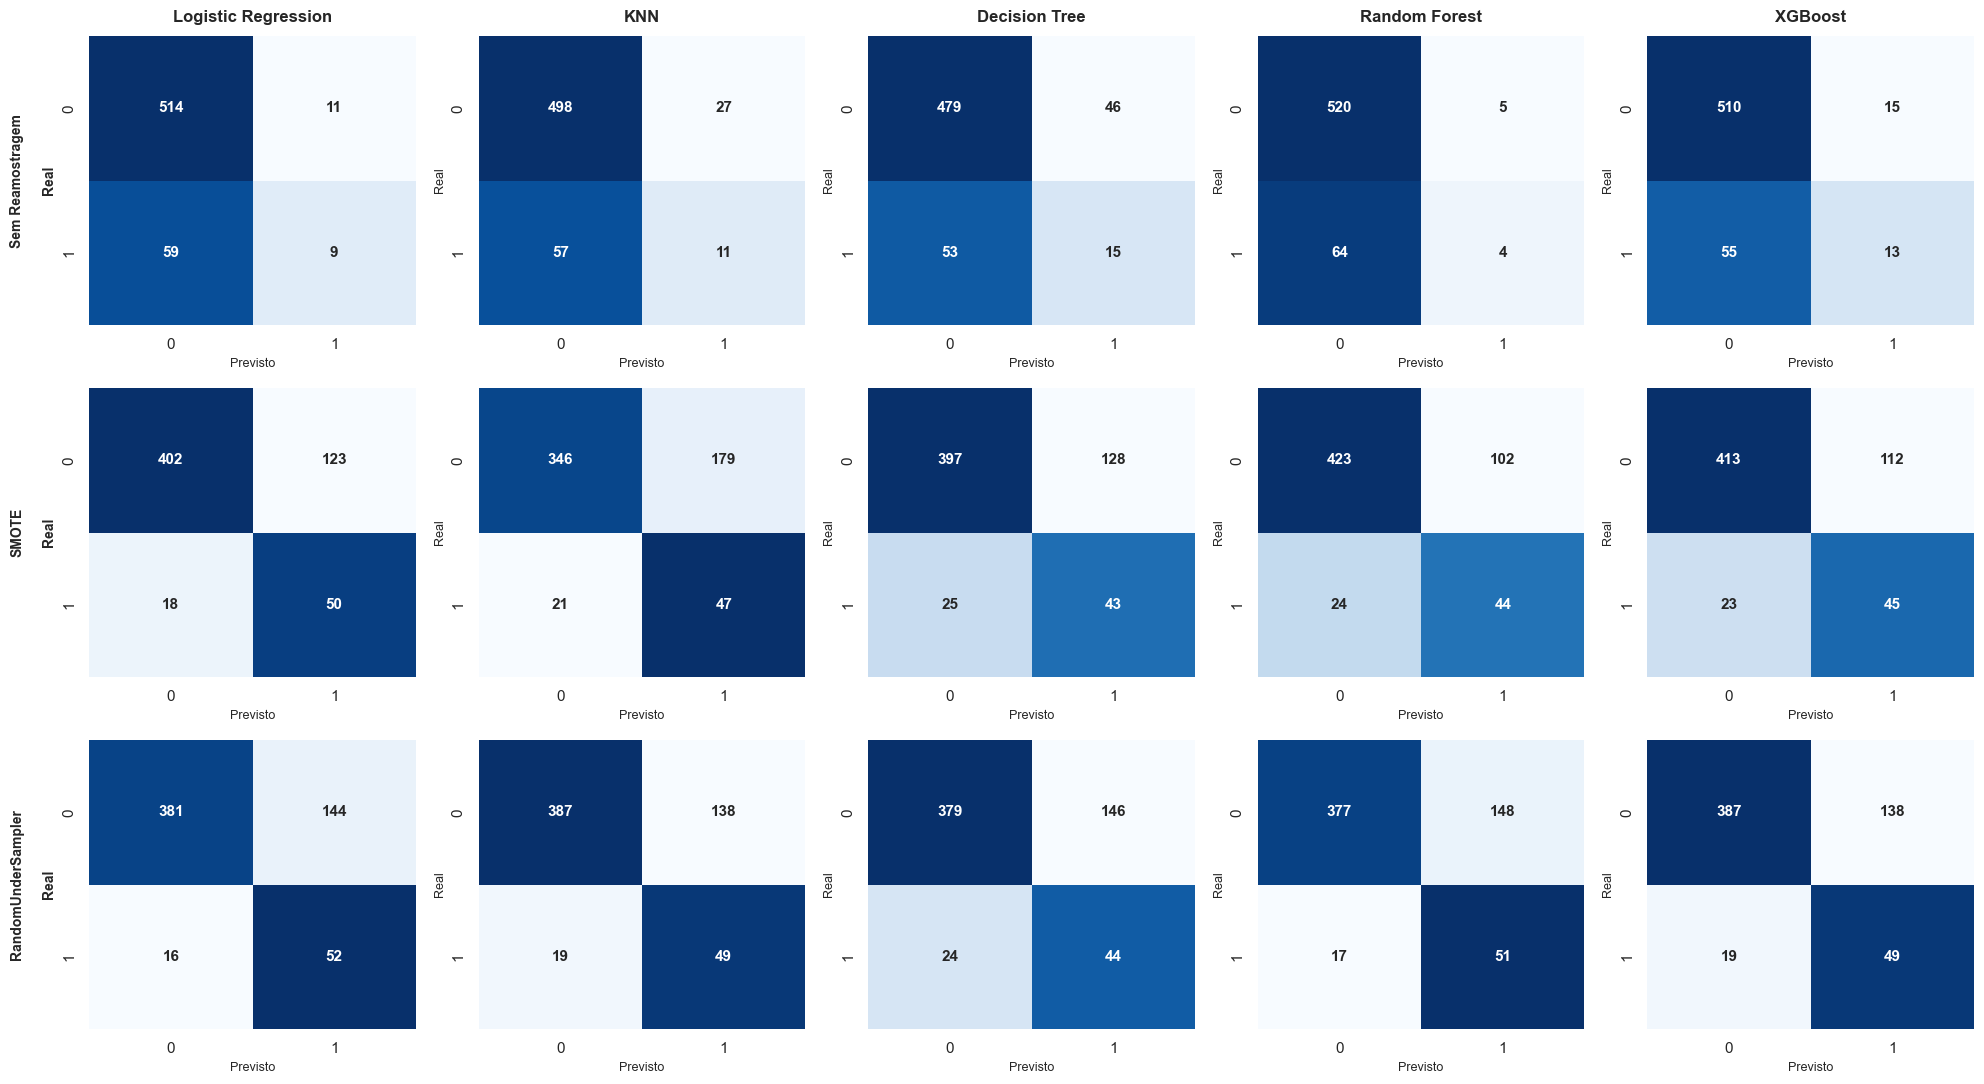

In [14]:
# Matrizes de Confusão Normalizadas (3 Abordagens x 5 Modelos)
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(20, 11))

for row_idx, strategy_name in enumerate(["Sem Reamostragem", "SMOTE", "RandomUnderSampler"]):
    for col_idx, model_name in enumerate(base_estimators.keys()):
        ax = axes[row_idx, col_idx]
        cm = cnf_matrices[(strategy_name, model_name)]
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

        sns.heatmap(
            cm_norm, annot=cm, cmap="Blues", fmt='g', cbar=False,
            ax=ax, annot_kws={"size": 11, "weight": "bold"}
        )
        if row_idx == 0:
            ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
        if col_idx == 0:
            ax.set_ylabel(f"{strategy_name}\n\nReal", fontsize=10, fontweight='bold')
        else:
            ax.set_ylabel("Real", fontsize=9)
        ax.set_xlabel("Previsto", fontsize=9)

plt.tight_layout()
plt.savefig('figuras/matrizes-confusao.png', dpi=300, bbox_inches='tight')
plt.show()